# ChronoState-KD Lite — Phase 2: Distil the adapters

**Goal:** train three LoRA adapters on the 0.5B student from the cached teacher logits:

| Run | Domain | Config | Purpose |
| --- | --- | --- | --- |
| `adapter-code` | code | `lite.yaml` (α=0.7) | KD code adapter for serving |
| `adapter-reasoning` | reasoning | `lite.yaml` (α=0.7) | KD reasoning adapter for serving |
| `adapter-reasoning-sft` | reasoning | `lite_sft.yaml` (α=0) | **ablation**: same data, steps, seed, LR — no KL term |

**Budget:** ~25 min per run on a T4 (≈70 steps for code, ≈94 for reasoning at batch 2 × accum 8), ~80 min total. Each run checkpoints to Drive every 50 steps and resumes if the session dies; a finished run is skipped on re-run.

**Gate to pass before Phase 3:** three `adapters/<run>/adapter_model.safetensors` on Drive (~9 MB each); CE *and* KL fall over training in the KD runs; `train_summary.json` per run.

Runtime → **T4 GPU**. Edit `GITHUB_URL`. If you only have time for one run now, set `RUNS` to a single entry — order does not matter.

In [1]:
GITHUB_URL = "https://github.com/DhanushGD/chronostate-kd.git"   # <-- edit
REPO_DIR   = "/content/chronostate-kd"
DRIVE_ROOT = "/content/drive/MyDrive/chronostate"
RUNS = [  # (run_name, domain, config)
    ("adapter-code",          "code",      "configs/lite.yaml"),
    ("adapter-reasoning",     "reasoning", "configs/lite.yaml"),
    ("adapter-reasoning-sft", "reasoning", "configs/lite_sft.yaml"),
]


## 1. Setup

In [2]:
import os, json, time, gc, torch
assert torch.cuda.is_available(), "Runtime -> Change runtime type -> T4 GPU"
print(torch.cuda.get_device_name(0))
if not os.path.exists(REPO_DIR):
    !git clone $GITHUB_URL $REPO_DIR
%cd $REPO_DIR
!git pull --ff-only
!pip install -q -r requirements.txt && pip install -q -e .
from google.colab import drive
drive.mount("/content/drive")
assert os.path.exists(f"{DRIVE_ROOT}/data/code.pt") and os.path.exists(f"{DRIVE_ROOT}/teacher_cache/reasoning/shard-0002.safetensors"), "Phase 1 artefacts missing on Drive"
from chronostate.config import load_config, to_dict
from chronostate.monitor import Monitor
from chronostate.train import train_adapter, build_student, quick_generate
from chronostate.data import SYSTEM_PROMPTS
mon = Monitor(f"{DRIVE_ROOT}/results/events.jsonl", run="phase2-distill")


Tesla T4
Cloning into '/content/chronostate-kd'...
remote: Enumerating objects: 62, done.
remote: Counting objects: 100% (62/62), done.
remote: Compressing objects: 100% (49/49), done.
remote: Total 62 (delta 14), reused 58 (delta 10), pack-reused 0 (from 0)
Receiving objects: 100% (62/62), 61.68 KiB | 6.85 MiB/s, done.
Resolving deltas: 100% (14/14), done.
/content/chronostate-kd
Already up to date.
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 43.1/43.1 MB 13.5 MB/s eta 0:00:00
  Installing build dependencies ... done
  Checking if build backend supports build_editable ... done
  Getting requirements to build editable ... done
  Preparing editable metadata (pyproject.toml) ... done
  Building editable for chronostate-kd (pyproject.toml) ... done
Mounted at /content/drive


## 2. Train
The loop (`chronostate/train.py`) prints every 10 steps: `loss`, `ce`, `kl`, grad-norm, LR, tokens/s. In the KD runs **both `ce` and `kl` should trend down**; in the SFT run `kl` is 0 by construction.

If Colab disconnects: reopen, run cells 1–2 again. Finished runs are skipped; an unfinished one resumes from its last 50-step checkpoint.

In [3]:
summaries = {}
for run_name, domain, config in RUNS:
    print("=" * 80); print(run_name, domain, config); print("=" * 80)
    cfg = load_config(config)
    t0 = time.time()
    summaries[run_name] = train_adapter(cfg, run_name, domain, DRIVE_ROOT, monitor=mon, resume=True)
    print(f"{run_name}: {(time.time()-t0)/60:.1f} min wall")
    gc.collect(); torch.cuda.empty_cache()


adapter-code code configs/lite.yaml


config.json:   0%|          | 0.00/659 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/7.30k [00:00<?, ?B/s]

vocab.json:   0%|          | 0.00/2.78M [00:00<?, ?B/s]

merges.txt:   0%|          | 0.00/1.67M [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/7.03M [00:00<?, ?B/s]

... (7 outputs left out)

Loading weights:   0%|          | 0/290 [00:00<?, ?it/s]

trainable params: 8,798,208 || all params: 502,830,976 || trainable%: 1.7497
[train:adapter-reasoning] step 1/94 loss 1.1262 ce 0.8240 kl 1.2557 gn 2.40 lr 2.00e-04 903 tok/s
[train:adapter-reasoning] step 10/94 loss 0.8032 ce 0.6669 kl 0.8616 gn 0.76 lr 1.96e-04 825 tok/s
[train:adapter-reasoning] step 20/94 loss 0.7347 ce 0.6761 kl 0.7598 gn 0.63 lr 1.82e-04 838 tok/s
[train:adapter-reasoning] step 30/94 loss 0.6635 ce 0.6057 kl 0.6882 gn 0.61 lr 1.58e-04 820 tok/s
[train:adapter-reasoning] step 40/94 loss 0.6331 ce 0.5834 kl 0.6544 gn 0.52 lr 1.27e-04 832 tok/s
[train:adapter-reasoning] step 50/94 loss 0.7873 ce 0.8095 kl 0.7778 gn 0.63 lr 9.32e-05 846 tok/s
[train:adapter-reasoning] step 60/94 loss 0.6874 ce 0.6207 kl 0.7159 gn 0.68 lr 6.02e-05 823 tok/s
[train:adapter-reasoning] step 70/94 loss 0.7326 ce 0.7815 kl 0.7117 gn 0.67 lr 3.17e-05 852 tok/s
[train:adapter-reasoning] step 80/94 loss 0.6305 ce 0.6153 kl 0.6369 gn 0.59 lr 1.12e-05 825 tok/s
[train:adapter-reasoning] step 90

Loading weights:   0%|          | 0/290 [00:00<?, ?it/s]

trainable params: 8,798,208 || all params: 502,830,976 || trainable%: 1.7497
[train:adapter-reasoning-sft] step 1/94 loss 0.8240 ce 0.8240 kl 0.0000 gn 1.72 lr 2.00e-04 912 tok/s
[train:adapter-reasoning-sft] step 10/94 loss 0.4969 ce 0.4969 kl 0.0000 gn 0.64 lr 1.96e-04 844 tok/s
[train:adapter-reasoning-sft] step 20/94 loss 0.5015 ce 0.5015 kl 0.0000 gn 0.50 lr 1.82e-04 828 tok/s
[train:adapter-reasoning-sft] step 30/94 loss 0.4204 ce 0.4204 kl 0.0000 gn 0.48 lr 1.58e-04 811 tok/s
[train:adapter-reasoning-sft] step 40/94 loss 0.4453 ce 0.4453 kl 0.0000 gn 0.40 lr 1.27e-04 836 tok/s
[train:adapter-reasoning-sft] step 50/94 loss 0.6161 ce 0.6161 kl 0.0000 gn 0.51 lr 9.32e-05 836 tok/s
[train:adapter-reasoning-sft] step 60/94 loss 0.4662 ce 0.4662 kl 0.0000 gn 0.49 lr 6.02e-05 817 tok/s
[train:adapter-reasoning-sft] step 70/94 loss 0.5515 ce 0.5515 kl 0.0000 gn 0.52 lr 3.17e-05 851 tok/s
[train:adapter-reasoning-sft] step 80/94 loss 0.4609 ce 0.4609 kl 0.0000 gn 0.44 lr 1.12e-05 799 tok

## 3. Loss curves
The plot for the write-up: CE and KL per step for every run, KD vs SFT on the same axes.

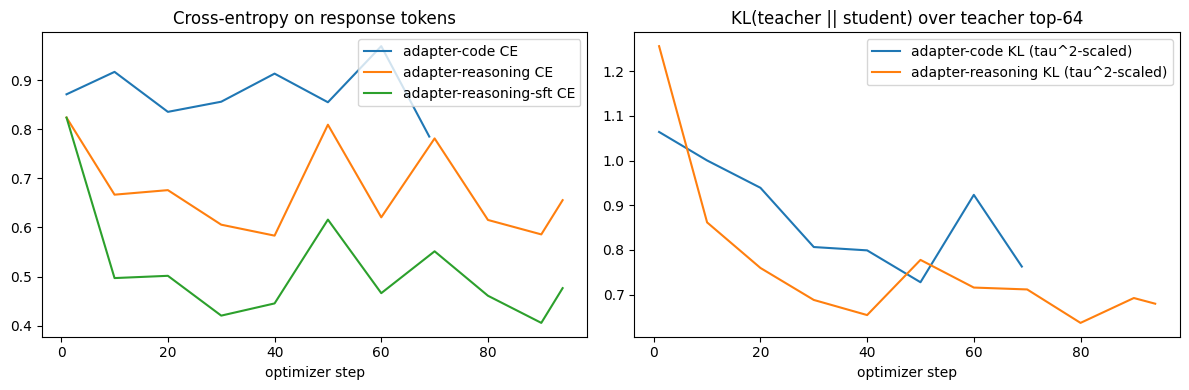

In [4]:
import matplotlib.pyplot as plt
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
for run_name, s in summaries.items():
    h = s["history"]; steps = [r["step"] for r in h]
    axes[0].plot(steps, [r["ce"] for r in h], label=f"{run_name} CE")
    if s["alpha"] > 0:
        axes[1].plot(steps, [r["kl"] for r in h], label=f"{run_name} KL (tau^2-scaled)")
axes[0].set_title("Cross-entropy on response tokens"); axes[0].set_xlabel("optimizer step"); axes[0].legend()
axes[1].set_title("KL(teacher || student) over teacher top-64"); axes[1].set_xlabel("optimizer step"); axes[1].legend()
os.makedirs("results", exist_ok=True)
plt.tight_layout(); plt.savefig("results/phase2_loss_curves.png", dpi=130); plt.show()


## 4. Smoke test each adapter
Not an evaluation (that is Phase 5) — just proof that each adapter changes the student's behaviour in the intended direction.

In [5]:
from peft import PeftModel
from transformers import AutoModelForCausalLM, AutoTokenizer, BitsAndBytesConfig
cfg = load_config("configs/lite.yaml")
bnb = BitsAndBytesConfig(load_in_4bit=True, bnb_4bit_quant_type="nf4", bnb_4bit_use_double_quant=True, bnb_4bit_compute_dtype=torch.float16)
tok = AutoTokenizer.from_pretrained(cfg.models.student)
base = AutoModelForCausalLM.from_pretrained(cfg.models.student, quantization_config=bnb, attn_implementation="sdpa", dtype=torch.float16, device_map={"": 0})
probes = {"code": "Write a Python function that returns the n-th Fibonacci number.",
          "reasoning": "A shop sells pens at $3 each. Ravi buys 4 pens and pays with a $20 bill. How much change does he get?"}
print("### BASE (no adapter)")
for d, p in probes.items(): print(f"[{d}]", quick_generate(base, tok, p, SYSTEM_PROMPTS[d], 80), "\n")
for run_name, domain, _ in RUNS:
    m = PeftModel.from_pretrained(base, f"{DRIVE_ROOT}/adapters/{run_name}")
    print(f"### {run_name}")
    print(quick_generate(m, tok, probes[domain], SYSTEM_PROMPTS[domain], 80), "\n")
    m.unload(); del m


Loading weights:   0%|          | 0/290 [00:00<?, ?it/s]

### BASE (no adapter)
[code] ```python
def fibonacci(n):
    if n == 0:
        return 0
    elif n == 1:
        return 1
    else:
        a, b = 0, 1
        for i in range(2, n + 1):
            a, b = b, a + b
        return b
```
This Python function calculates the 

[reasoning] To determine how much change Ravi gets from his $20 bill, we need to follow these steps:

1. Calculate the total cost of the 4 pens.
   - Each pen costs $3.
   - Therefore, the cost for 4 pens is \(4 \times 3 = 12\) dollars.

2. Subtract the amount paid from the total cost.
   - R 

### adapter-code
To solve this problem, we can use an iterative approach to compute the nth Fibonacci number. Here's how you can implement it:

```python
def fibonacci(n):
    if n <= 0:
        return "Input should be a positive integer"
    
    # Initialize the first two Fibonacci numbers
    fib = [0, 1]
    
    # Compute the nth Fibonacci number iteratively
 

### adapter-reasoning
To find out how much change Ravi gets, 

## 5. Save summaries for the repo

In [6]:
slim = {k: {kk: vv for kk, vv in v.items() if kk != "history"} for k, v in summaries.items()}
json.dump(slim, open("results/phase2_train_summary.json", "w"), indent=2)
json.dump(summaries, open(f"{DRIVE_ROOT}/results/phase2_train_summary_full.json", "w"), indent=2)
mon.close()
print(json.dumps(slim, indent=2))
!ls -la $DRIVE_ROOT/adapters/*


{
  "adapter-code": {
    "run_name": "adapter-code",
    "domain": "code",
    "config": "configs/lite.yaml",
    "alpha": 0.7,
    "tau": 2.0,
    "rows": 1101,
    "steps": 69,
    "resumed_from": 0,
    "final_loss": 0.7696232795715332,
    "final_ce": 0.7852743310587746,
    "final_kl": 0.7629156538418361,
    "seconds": 287.075745344162,
    "response_tokens_seen": 139280,
    "adapter_mb": 35.237104,
    "vram_peak_gb": 2.451342848
  },
  "adapter-reasoning": {
    "run_name": "adapter-reasoning",
    "domain": "reasoning",
    "config": "configs/lite.yaml",
    "alpha": 0.7,
    "tau": 2.0,
    "rows": 1500,
    "steps": 94,
    "resumed_from": 0,
    "final_loss": 0.6725823680559794,
    "final_ce": 0.6556908388932546,
    "final_kl": 0.6798215955495834,
    "seconds": 366.57369089126587,
    "response_tokens_seen": 165427,
    "adapter_mb": 35.237104,
    "vram_peak_gb": 2.45112832
  },
  "adapter-reasoning-sft": {
    "run_name": "adapter-reasoning-sft",
    "domain": "reaso

## Gate checklist
- [ ] three adapters on Drive, `adapter_model.safetensors` ≈ 9 MB each
- [ ] KD runs: `ce` and `kl` both lower at the end than at step 1
- [ ] SFT run: `kl` = 0 throughout; its final `ce` is comparable to (likely a bit lower than) the KD reasoning run's `ce` — that is expected, SFT optimises CE only
- [ ] `results/phase2_train_summary.json` and `results/phase2_loss_curves.png` downloaded and committed

Report back: the three final `loss / ce / kl` lines, step counts, minutes per run, peak VRAM, and paste the smoke-test outputs.